# Лабораторная работа №2: классификация (Titanic)

**Задача:** по данным о пассажире Титаника предсказать, выжил ли он (`Survived = 1`) или нет (`Survived = 0`). Это **бинарная классификация**.

**Основная метрика:** F1-score для класса `Survived = 1` (порог: **F1 > 0.70**). Дополнительно: Accuracy, Precision, Recall, confusion matrix.

**Данные:** [Titanic Dataset](https://www.kaggle.com/datasets/yasserh/titanic-dataset), 891 пассажир.

**План:**
1. Загрузка и первичный анализ данных (EDA)
2. Новые признаки и отбор признаков (что может привести к утечке или запоминанию пассажиров)
3. Разбиение на train / test со стратификацией
4. Предобработка: пропуски, категориальные признаки, масштабирование
5. Метрики и Dummy baseline
6. Модели: Decision Tree, Random Forest, Gradient Boosting, SVM, KNN
7. Честное сравнение моделей
8. Feature importance
9. Анализ ошибок лучшей модели

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42          # фиксируем случайность -> эксперимент воспроизводим
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 50)

## 1. Загрузка данных

In [2]:
df = pd.read_csv("data/archive/Titanic-Dataset.csv")
print("Размер таблицы:", df.shape)
df.head()

Размер таблицы: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Первичный анализ данных (EDA)

### 2.1 Типы признаков, пропуски, дубликаты

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
missing = pd.DataFrame({
    "пропусков": df.isna().sum(),
    "доля, %": (df.isna().mean() * 100).round(1),
    "уникальных значений": df.nunique(),
})
print("Полных дубликатов строк:", df.duplicated().sum())
missing

Полных дубликатов строк: 0


,пропусков,"доля, %",уникальных значений
PassengerId,0,0.0,891
Survived,0,0.0,2
Pclass,0,0.0,3
Name,0,0.0,891
Sex,0,0.0,2
Age,177,19.9,88
SibSp,0,0.0,7
Parch,0,0.0,7
Ticket,0,0.0,681
Fare,0,0.0,248


**Выводы:**
- **Типы признаков:**
  - числовые: `Age` (возраст), `Fare` (цена билета), `SibSp` (братья/сёстры/супруги на борту), `Parch` (родители/дети на борту);
  - категориальные: `Sex`, `Embarked` (порт посадки: C — Шербур, Q — Квинстаун, S — Саутгемптон), `Pclass` (класс каюты 1/2/3 — записан числом, но это упорядоченная категория);
  - текстовые / идентификаторы: `PassengerId`, `Name`, `Ticket`, `Cabin`.
- **Пропуски:**
  - `Age` — 177 (≈20%): слишком много, чтобы удалять строки → заполним **медианой** (медиана устойчива к выбросам, в отличие от среднего);
  - `Cabin` — 687 (≈77%): заполнять бессмысленно — используем только факт «каюта известна / неизвестна»;
  - `Embarked` — 2: заполним **самым частым** значением.
- **Дубликатов нет.**
- `PassengerId` и `Name` уникальны у каждого пассажира, `Ticket` почти уникален (681 из 891) — это признаки, которые требуют отдельного решения (раздел 2.5).

### 2.2 Распределение целевой переменной

Survived
0    549
1    342
Name: count, dtype: int64

Доля выживших: 0.384


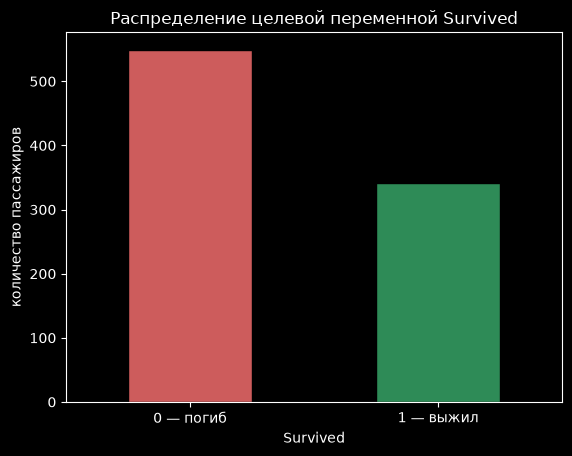

In [5]:
counts = df["Survived"].value_counts().sort_index()
print(counts)
print("\nДоля выживших:", round(df["Survived"].mean(), 3))

counts.plot(kind="bar", color=["indianred", "seagreen"], edgecolor="black", rot=0)
plt.xticks([0, 1], ["0 — погиб", "1 — выжил"])
plt.title("Распределение целевой переменной Survived")
plt.ylabel("количество пассажиров")
plt.show()

**Выводы:**
- Выжило **38.4%** пассажиров (342 из 891), погибло 61.6%. Классы **несбалансированы**.
- Поэтому **Accuracy обманчива**: модель, которая всегда говорит «погиб», уже получит accuracy ≈ 0.62, ничего не понимая. Нам важно, насколько хорошо модель находит **выживших** — это меряют Precision, Recall и F1 для класса 1.
- При разбиении на train/test нужно **сохранить соотношение классов** (стратификация).

### 2.3 Выживаемость по категориальным признакам

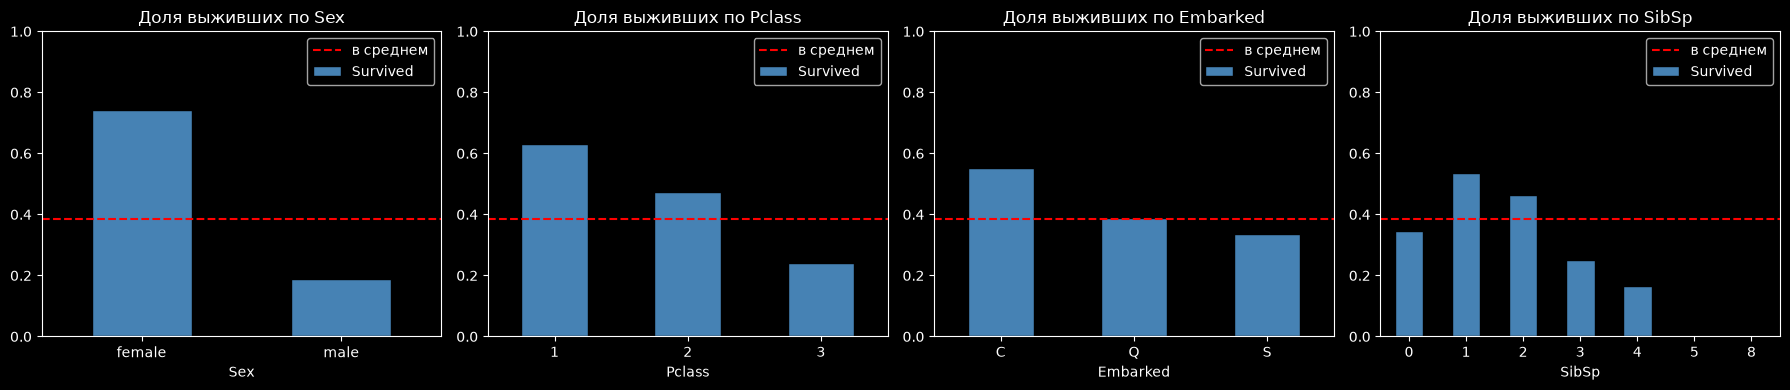

Pclass     1     2     3
Sex                     
female  0.97  0.92  0.50
male    0.37  0.16  0.14


In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["Sex", "Pclass", "Embarked", "SibSp"]):
    rate = df.groupby(col)["Survived"].mean()
    rate.plot(kind="bar", ax=ax, color="steelblue", edgecolor="black", rot=0)
    ax.axhline(df["Survived"].mean(), color="red", ls="--", label="в среднем")
    ax.set_title(f"Доля выживших по {col}")
    ax.set_ylim(0, 1)
    ax.legend()
plt.tight_layout()
plt.show()

print(pd.crosstab([df["Sex"]], df["Pclass"], values=df["Survived"], aggfunc="mean").round(2))

**Выводы:**
- **Пол — самый сильный фактор:** выжило ≈74% женщин и только ≈19% мужчин. Это отражает правило эвакуации «женщины и дети — первыми».
- **Класс каюты:** 1-й класс — 63%, 2-й — 47%, 3-й — 24%. Каюты 1-го класса были ближе к шлюпочной палубе, а у пассажиров 1-го класса было больше возможностей попасть в шлюпки.
- **Пол × класс** (таблица): женщины 1–2 класса выжили почти все (97% и 92%), женщины 3-го класса — только 50%; мужчины 1-го класса — 37%, 2–3-го — около 15%. Признаки **взаимодействуют**: влияние класса разное для мужчин и женщин — это подсказка, что пригодятся модели, умеющие учитывать взаимодействия (деревья).
- **Порт посадки:** из Шербура (C) выжило 55%, из Саутгемптона (S) — 34%. Скорее всего, это не влияние порта, а то, что в Шербуре садилось больше пассажиров 1-го класса (порт связан с классом).
- `SibSp`: одиночки и пассажиры с 1 родственником выживали чаще, чем из больших семей.

### 2.4 Возраст и стоимость билета

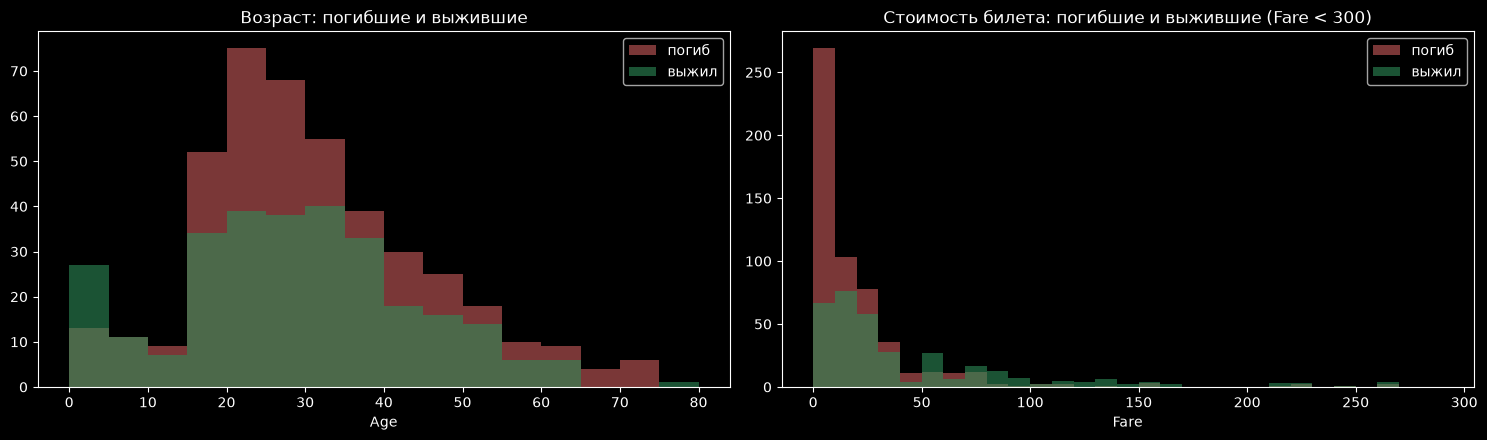

          mean  size
Age                 
(0, 12]   0.58    69
(12, 18]  0.43    70
(18, 30]  0.36   270
(30, 45]  0.43   202
(45, 60]  0.41    81
(60, 80]  0.23    22


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
bins_age = np.arange(0, 85, 5)
axes[0].hist(df.loc[df["Survived"] == 0, "Age"].dropna(), bins=bins_age, alpha=0.6, label="погиб", color="indianred")
axes[0].hist(df.loc[df["Survived"] == 1, "Age"].dropna(), bins=bins_age, alpha=0.6, label="выжил", color="seagreen")
axes[0].set_title("Возраст: погибшие и выжившие")
axes[0].set_xlabel("Age")
axes[0].legend()

bins_fare = np.arange(0, 300, 10)
axes[1].hist(df.loc[df["Survived"] == 0, "Fare"], bins=bins_fare, alpha=0.6, label="погиб", color="indianred")
axes[1].hist(df.loc[df["Survived"] == 1, "Fare"], bins=bins_fare, alpha=0.6, label="выжил", color="seagreen")
axes[1].set_title("Стоимость билета: погибшие и выжившие (Fare < 300)")
axes[1].set_xlabel("Fare")
axes[1].legend()
plt.tight_layout()
plt.show()

age_group = pd.cut(df["Age"], bins=[0, 12, 18, 30, 45, 60, 80])
print(df.groupby(age_group, observed=True)["Survived"].agg(["mean", "size"]).round(2))

**Выводы:**
- **Возраст:** дети до 12 лет выживали чаще всех (58%), пожилые старше 60 — реже всех (23%). Для взрослых 18–60 лет разница небольшая. Связь **нелинейная**: важен не «возраст вообще», а «ребёнок или нет».
- **Стоимость билета:** среди дешёвых билетов (до ~10) явно преобладают погибшие, среди дорогих — выжившие. `Fare` во многом дублирует `Pclass` (дорогие билеты — 1-й класс).
- У `Fare` длинный правый хвост (до 512) — для алгоритмов на расстояниях (KNN, SVM) понадобится масштабирование.

### 2.5 Признаки, требующие отдельного решения: утечка и «запоминание» пассажиров

In [8]:
print("PassengerId: уникальных", df["PassengerId"].nunique(), "из", len(df))
print("Name:       уникальных", df["Name"].nunique(), "из", len(df))
print("Ticket:     уникальных", df["Ticket"].nunique(), "из", len(df))
print("Cabin:      уникальных", df["Cabin"].nunique(), "из", df["Cabin"].notna().sum(), "заполненных")
print()
print("Примеры значений:")
df[["PassengerId", "Name", "Ticket", "Cabin"]].head(8)

PassengerId: уникальных 891 из 891
Name:       уникальных 891 из 891
Ticket:     уникальных 681 из 891
Cabin:      уникальных 147 из 204 заполненных

Примеры значений:


,PassengerId,Name,Ticket,Cabin
0,1,"Braund, Mr. Owen Harris",A/5 21171,NaN
1,2,"Cumings, Mrs. John Bradley (Florence Briggs Th...",PC 17599,C85
2,3,"Heikkinen, Miss. Laina",STON/O2. 3101282,NaN
3,4,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",113803,C123
4,5,"Allen, Mr. William Henry",373450,NaN
5,6,"Moran, Mr. James",330877,NaN
6,7,"McCarthy, Mr. Timothy J",17463,E46
7,8,"Palsson, Master. Gosta Leonard",349909,NaN


**Решения по «опасным» признакам:**

| Признак | Проблема | Решение |
|---|---|---|
| `PassengerId` | Просто порядковый номер, уникален у каждого. Никакого смысла для выживания не несёт; модель может «запомнить» конкретных пассажиров по номеру | **Удаляем** (проверим в разделе 15, что будет, если его оставить) |
| `Name` | Уникально у каждого → идентифицирует пассажира, модель может запомнить «этот человек выжил» | **Удаляем**, но извлекаем **титул** (Mr, Mrs, Miss, Master...) — он несёт обобщаемую информацию о поле, возрасте и статусе |
| `Ticket` | 681 уникальное значение из 891 — почти идентификатор; формат хаотичный | **Удаляем** |
| `Cabin` | 77% пропусков, номер каюты почти уникален | **Удаляем номер**, но создаём признак `HasCabin` — известна ли каюта (обычно известна у пассажиров 1-го класса) |

**Утечка целевой переменной:** в данных нет признаков, вычисленных *после* катастрофы (например, номер спасательной шлюпки или номер опознанного тела — в некоторых версиях датасета такие столбцы есть, и они почти напрямую выдают ответ). В нашей версии их нет, но важно понимать: признак, известный только после события, использовать нельзя.

## 3. Новые признаки

- **`Title`** — титул из имени. Редкие титулы (Dr, Rev, Col, Countess, ...) объединяем в `Rare`, французские формы приводим к английским (Mlle → Miss, Mme → Mrs).
- **`FamilySize`** = `SibSp` + `Parch` + 1 — размер семьи на борту.
- **`HasCabin`** — известна ли каюта (1/0).

Эти признаки вычисляются **по каждой строке отдельно**, без статистик по всей выборке (средних, частот и т.п.), поэтому их можно строить до разбиения на train/test — утечки нет.

In [9]:
def add_features(data):
    """Новые признаки. Каждый считается по одной строке (без статистик по выборке),
    поэтому их можно строить до разбиения — утечки информации нет."""
    data = data.copy()
    # Титул из имени: "Braund, Mr. Owen Harris" -> "Mr"
    data["Title"] = data["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip()
    data["Title"] = data["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    data["Title"] = data["Title"].where(data["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
    # Размер семьи на борту: сам пассажир + братья/сёстры/супруги + родители/дети
    data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
    # Известен ли номер каюты (сам номер почти уникален, а факт его наличия информативен)
    data["HasCabin"] = data["Cabin"].notna().astype(int)
    return data

df = add_features(df)
print(df["Title"].value_counts())
print()
for col in ["Title", "FamilySize", "HasCabin"]:
    print(df.groupby(col)["Survived"].agg(["mean", "size"]).round(2), "\n")

Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64

        mean  size
Title             
Master  0.57    40
Miss    0.70   185
Mr      0.16   517
Mrs     0.79   126
Rare    0.35    23 

            mean  size
FamilySize            
1           0.30   537
2           0.55   161
3           0.58   102
4           0.72    29
5           0.20    15
6           0.14    22
7           0.33    12
8           0.00     6
11          0.00     7 

          mean  size
HasCabin            
0         0.30   687
1         0.67   204 



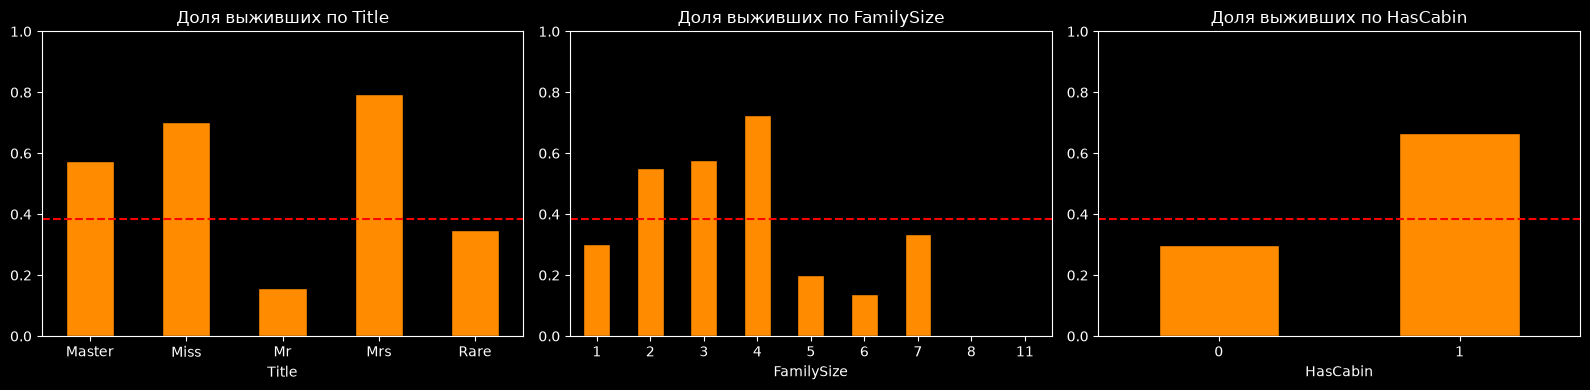

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Title", "FamilySize", "HasCabin"]):
    df.groupby(col)["Survived"].mean().plot(kind="bar", ax=ax, color="darkorange", edgecolor="black", rot=0)
    ax.axhline(df["Survived"].mean(), color="red", ls="--")
    ax.set_title(f"Доля выживших по {col}")
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

**Выводы:**
- `Title` очень информативен: Mr — 16% выживших, Mrs — 79%, Miss — 70%, **Master** (мальчики) — 57%, т.е. мальчики выживали намного чаще взрослых мужчин. Титул объединяет пол и возраст — это та самая «женщины и дети первыми».
- `FamilySize`: одиночки — 30%, семьи из 2–4 человек — 55–72%, большие семьи (5+) — 0–33%. Связь **нелинейная** (максимум в середине): большой семье труднее было вместе добраться до шлюпок, а одиночки — в основном мужчины 3-го класса.
- `HasCabin`: с известной каютой выжило 67%, без — 30% (каюта известна в основном у 1-го класса).

## 4. Разбиение на обучающую и тестовую выборки

- **80% train / 20% test** (712 / 179 пассажиров).
- **Стратификация по `Survived`** (`stratify=y`): доля выживших в train и test одинаковая (≈38%). Без неё случайное разбиение могло бы сдвинуть соотношение классов, и метрики на тесте были бы искажены.
- `random_state=42` — воспроизводимость.
- **Одно разбиение для всех моделей** — честное сравнение.
- **Тест используется только для финальной оценки.** Гиперпараметры подбираем по **кросс-валидации на train** (`GridSearchCV`, 5 фолдов со стратификацией, метрика F1).

In [11]:
from sklearn.model_selection import train_test_split

num_features = ["Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize", "HasCabin"]
cat_features = ["Sex", "Embarked", "Title"]
# PassengerId, Name, Ticket, Cabin в модель НЕ подаём (см. выводы EDA)

X = df[num_features + cat_features]
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Доля выживших: train =", round(y_train.mean(), 3), " test =", round(y_test.mean(), 3))
print("\nПропуски в train:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

Train: (712, 10)  Test: (179, 10)
Доля выживших: train = 0.383  test = 0.385

Пропуски в train:
Age         137
Embarked      2
dtype: int64


## 5. Предобработка данных

Все шаги собраны в `Pipeline` + `ColumnTransformer`. Это гарантирует, что **параметры преобразований вычисляются только на train** (в том числе внутри каждого фолда кросс-валидации), а к тесту лишь применяются:

| Шаг | Для чего | Что «учится» на train |
|---|---|---|
| `SimpleImputer(strategy="median")` для числовых | Заполнить пропуски `Age` | медиана возраста |
| `SimpleImputer(strategy="most_frequent")` для категориальных | Заполнить пропуски `Embarked` | самый частый порт |
| `OneHotEncoder` | Превратить категории в числа: `Sex` → `Sex_female`, `Sex_male` (0/1) | список категорий |
| `StandardScaler` (только для SVM и KNN) | Привести числовые признаки к одному масштабу | среднее и std |

**Почему One-Hot, а не номера категорий (S=0, C=1, Q=2)?** Номера создали бы ложный порядок и «расстояния» (будто Q «больше» S), что исказило бы SVM и KNN. One-Hot кодирует каждую категорию отдельным столбцом 0/1 без порядка. `Pclass` оставляем числом: у классов есть естественный порядок (1 > 2 > 3 по уровню).

**Для каких алгоритмов важно масштабирование?**
- **KNN и SVM — важно.** Они работают с **расстояниями** между объектами. Без масштабирования `Fare` (0–512) и `Age` (0–80) полностью «перекричат» признаки 0/1 вроде `Sex_female`: разница в цене билета на 50 даст расстояние в 50, а разный пол — всего 1.
- **Деревья (Decision Tree, Random Forest, Gradient Boosting) — не нужно.** Дерево делит выборку по порогу одного признака («Fare > 26?»); масштабирование не меняет порядок значений, а значит, и разбиения.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def make_preprocessor(scale):
    """Предобработка. Медианы, самые частые значения, категории и параметры
    масштабирования вычисляются только при .fit() — т.е. только на train."""
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    cat_steps = [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_features),
        ("cat", Pipeline(cat_steps), cat_features),
    ])


# пример: что получается после предобработки (обучаем только на train)
demo = make_preprocessor(scale=True).fit(X_train)
feature_names = [n.split("__", 1)[1] for n in demo.get_feature_names_out()]
print("Признаков после предобработки:", len(feature_names))
print(feature_names)
pd.DataFrame(demo.transform(X_train[:5]), columns=feature_names).round(2)

Признаков после предобработки: 17
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'HasCabin', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare']


,Pclass,Age,SibSp,Parch,Fare,FamilySize,HasCabin,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,0.83,-0.08,-0.47,-0.47,0.51,-0.56,-0.54,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,-0.37,-0.08,-0.47,-0.47,-0.66,-0.56,-0.54,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,-1.57,-0.08,-0.47,-0.47,3.96,-0.56,1.86,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3,0.83,-0.89,-0.47,0.73,-0.47,0.07,-0.54,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,-0.37,0.11,0.48,0.73,-0.12,0.70,-0.54,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


После предобработки 10 исходных признаков превратились в 17 числовых (категориальные развернулись в столбцы 0/1). В примере выше числовые признаки отмасштабированы (среднее 0, std 1).

## 6. Метрики

Матрица ошибок (confusion matrix) — таблица 2×2 «истинный класс × предсказанный класс»:

| | предсказано: погиб (0) | предсказано: выжил (1) |
|---|---|---|
| **на самом деле погиб (0)** | **TN** — верно сказали «погиб» | **FP** — ложная тревога: сказали «выжил», а человек погиб |
| **на самом деле выжил (1)** | **FN** — пропуск: сказали «погиб», а человек выжил | **TP** — верно нашли выжившего |

- **Accuracy** = (TP + TN) / всех — доля правильных ответов. При дисбалансе обманчива.
- **Precision** = TP / (TP + FP) — из тех, кого модель назвала выжившими, сколько действительно выжили. «Насколько можно верить ответу „выжил“».
- **Recall** = TP / (TP + FN) — из всех реально выживших, скольких модель нашла. «Сколько выживших мы не пропустили».
- **F1** = 2 · Precision · Recall / (Precision + Recall) — гармоническое среднее. Высоким оно бывает, только если **и** Precision, **и** Recall высокие; если одна из них близка к 0, F1 тоже близок к 0.

**FP и FN в контексте Титаника:**
- **False Positive** — модель предсказала, что пассажир **выживет, а он погиб**. Типичный случай — женщина 3-го класса: «женщина → выжила», но в 3-м классе выжила лишь половина женщин.
- **False Negative** — модель предсказала, что пассажир **погибнет, а он выжил**. Типичный случай — мужчина 1-го класса.
- Какая ошибка хуже, зависит от применения. Если бы модель помогала, например, решать, кого искать в первую очередь, FN (пропущенный выживший) был бы опаснее. F1 учитывает обе ошибки сбалансированно.

Вспомогательные функции: метрики на train и test, confusion matrix, подбор гиперпараметров по CV (метрика F1).

In [13]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

results = {}          # метрики всех моделей на ОДНОЙ тестовой выборке
predictions = {}      # предсказания на тесте — для confusion matrix и анализа ошибок


def metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
    }


def evaluate(name, model):
    """Метрики на train и test + confusion matrix на test."""
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    results[name] = metrics(y_test, pred_test)
    predictions[name] = pred_test
    table = pd.DataFrame({"train": metrics(y_train, pred_train), "test": results[name]}).T.round(3)
    print(name)
    display(table)
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred_test, display_labels=["погиб (0)", "выжил (1)"], cmap="Blues", colorbar=False)
    plt.title(f"{name}: confusion matrix (test)")
    plt.show()


def tune(name, estimator, param_grid, scale):
    """Подбор гиперпараметров по 5-fold CV на train с метрикой F1."""
    pipe = Pipeline([("prep", make_preprocessor(scale)), ("model", estimator)])
    search = GridSearchCV(pipe, param_grid, scoring="f1", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    print(f"{name}: лучшие параметры {search.best_params_}, CV F1 = {search.best_score_:.3f}")
    return search.best_estimator_


def importances(model):
    names = [n.split("__", 1)[1] for n in model.named_steps["prep"].get_feature_names_out()]
    return pd.Series(model.named_steps["model"].feature_importances_, index=names).sort_values()

## 7. Dummy baseline

Всегда предсказывает самый частый класс — «погиб».

Dummy (most frequent)


,Accuracy,Precision,Recall,F1
train,0.617,0.0,0.0,0.0
test,0.615,0.0,0.0,0.0


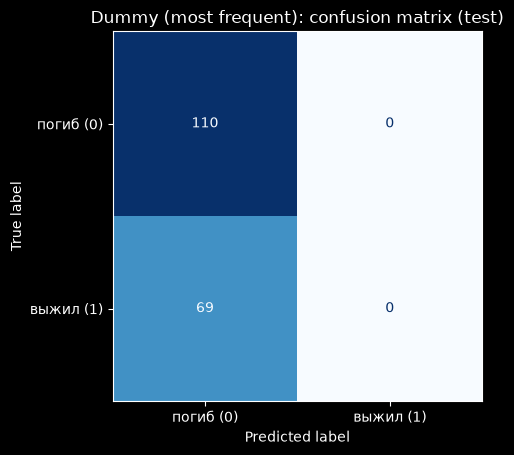

In [14]:
from sklearn.dummy import DummyClassifier

dummy = Pipeline([("prep", make_preprocessor(scale=False)),
                  ("model", DummyClassifier(strategy="most_frequent"))])
dummy.fit(X_train, y_train)
evaluate("Dummy (most frequent)", dummy)

**Вывод:** Accuracy ≈ 0.62 — кажется, что «неплохо», но **F1 = 0, Precision = 0, Recall = 0**: модель не нашла ни одного выжившего (TP = 0, все 69 выживших в тесте — FN). Это наглядно показывает, почему Accuracy при дисбалансе классов обманчива и почему основная метрика — F1 для класса 1. Любая полезная модель должна заметно превзойти этот baseline по F1.

## 8. Decision Tree

Дерево решений — последовательность вопросов «признак > порог?». На каждом шаге выбирается разбиение, которое лучше всего разделяет выживших и погибших (минимизирует неоднородность групп — критерий Джини). В листе — класс большинства попавших туда пассажиров.

### 8.1 Неограниченное дерево: проверка на переобучение

In [15]:
from sklearn.tree import DecisionTreeClassifier

tree_full = Pipeline([("prep", make_preprocessor(scale=False)),
                      ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))])
tree_full.fit(X_train, y_train)
print("Глубина неограниченного дерева:", tree_full.named_steps["model"].get_depth(),
      " листьев:", tree_full.named_steps["model"].get_n_leaves())
print("F1 train:", round(f1_score(y_train, tree_full.predict(X_train)), 3),
      " F1 test:", round(f1_score(y_test, tree_full.predict(X_test)), 3))

Глубина неограниченного дерева: 22  листьев: 163
F1 train: 0.983  F1 test: 0.734


**Переобучение:** дерево без ограничений выросло до глубины 22 и 163 листьев — почти отдельный лист на каждую небольшую группу пассажиров. На train F1 = 0.98 (почти всё запомнило), на тесте — 0.73. Большой разрыв train/test — явный признак **переобучения**: дерево выучило не закономерности, а особенности конкретных обучающих пассажиров (шум).

### 8.2 Подбор глубины по кросс-валидации

Ограничиваем сложность: `max_depth` (максимальная глубина) и `min_samples_leaf` (минимум пассажиров в листе), значения выбираем по CV на train.

Decision Tree: лучшие параметры {'model__max_depth': 3, 'model__min_samples_leaf': 1}, CV F1 = 0.765
Decision Tree


,Accuracy,Precision,Recall,F1
train,0.831,0.812,0.729,0.768
test,0.832,0.820,0.725,0.769


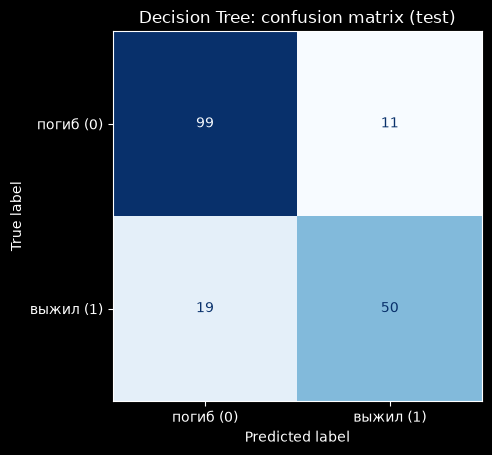

In [16]:
tree = tune(
    "Decision Tree",
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    {"model__max_depth": [2, 3, 4, 5, 6, 8, 10, None], "model__min_samples_leaf": [1, 5, 10]},
    scale=False,
)
evaluate("Decision Tree", tree)

**Анализ Decision Tree:**
- По CV выбрано **очень простое дерево: глубина 3**. F1 на train (0.768) и test (0.769) почти совпадают — **переобучения нет**. При этом на тесте ограниченное дерево **лучше** неограниченного (0.769 против 0.734): упрощение модели улучшило обобщающую способность.
- Confusion matrix: 50 выживших найдено (TP), 19 пропущено (FN), 11 ложных тревог (FP). Модель чаще **пропускает** выживших, чем ошибочно «спасает» погибших: Precision (0.82) выше Recall (0.73).

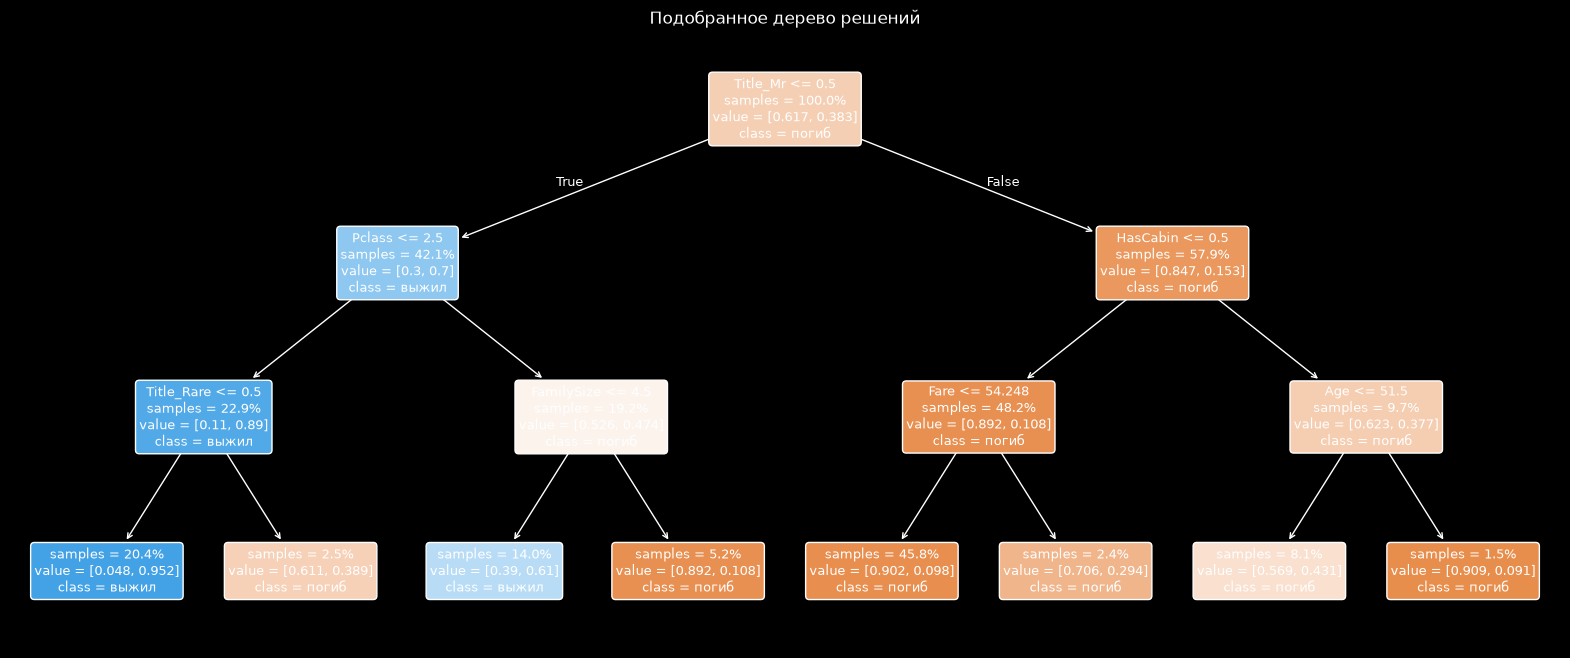

In [17]:
from sklearn.tree import plot_tree

names = [n.split("__", 1)[1] for n in tree.named_steps["prep"].get_feature_names_out()]
plt.figure(figsize=(20, 8))
plot_tree(tree.named_steps["model"], feature_names=names, class_names=["погиб", "выжил"],
          filled=True, rounded=True, fontsize=9, impurity=False, proportion=True)
plt.title("Подобранное дерево решений")
plt.show()

**Как читать дерево** (в каждом узле — доля пассажиров и доли классов):
- **Первый вопрос — `Title_Mr`**: взрослый мужчина или нет. Это главное разбиение — «женщины и дети» против взрослых мужчин.
- **Женщины и дети** (`Title_Mr = 0`):
  - 1–2 класс → **выжил** (кроме редких титулов `Rare` — в основном мужчины-врачи, священники, офицеры);
  - 3 класс → **выжил**, если семья не больше 4 человек, иначе **погиб** (большие семьи 3-го класса почти не спаслись).
- **Взрослые мужчины** (`Title_Mr = 1`): дерево ещё делит их по `HasCabin`, `Fare`, `Age`, но **во всех листьях предсказание — «погиб»**: эти разбиения лишь уточняют доли, а большинство мужчин в каждой группе погибло.
- По сути дерево выучило правило «**женщины и дети первыми, но в 3-м классе — только из небольших семей**». Это хорошо интерпретируемая модель.

Parch           0.000
SibSp           0.000
Sex_female      0.000
Title_Master    0.000
Embarked_S      0.000
Embarked_Q      0.000
Embarked_C      0.000
Sex_male        0.000
Title_Mrs       0.000
Title_Miss      0.000
Fare            0.008
Age             0.013
HasCabin        0.050
Title_Rare      0.061
FamilySize      0.082
Pclass          0.155
Title_Mr        0.630
dtype: float64


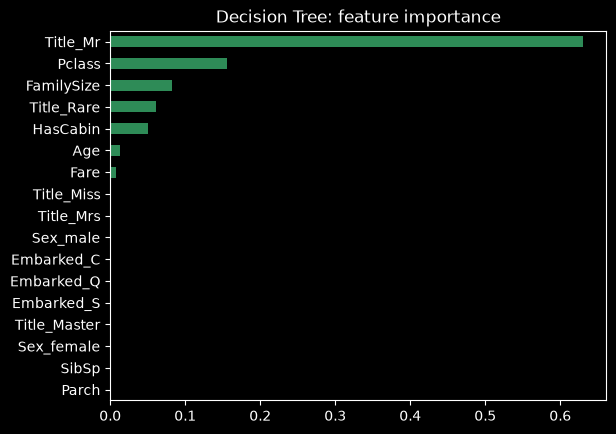

In [18]:
tree_imp = importances(tree)
print(tree_imp.round(3))
tree_imp.plot(kind="barh", color="seagreen")
plt.title("Decision Tree: feature importance")
plt.show()

**Feature importance дерева:** почти вся важность у `Title_Mr` (0.63), затем `Pclass` (0.16) и `FamilySize` (0.08). Признак `Sex` получил **0** — не потому, что пол неважен, а потому что `Title_Mr` уже содержит информацию о поле (и о возрасте), и дереву глубины 3 оказалось достаточно одного из этих признаков. Одиночное дерево «выбирает» один из похожих признаков и игнорирует остальные — его важности неустойчивы.

## 9. Random Forest

Случайный лес — 500 деревьев, каждое обучается на бутстрэп-выборке пассажиров и в каждом разбиении смотрит на случайное подмножество признаков. Итоговый ответ — голосование деревьев (класс, за который большинство). Усреднение множества разных деревьев уменьшает переобучение одиночного дерева.

Random Forest: лучшие параметры {'model__max_depth': 4, 'model__min_samples_leaf': 3}, CV F1 = 0.775
Random Forest


,Accuracy,Precision,Recall,F1
train,0.837,0.815,0.744,0.778
test,0.804,0.774,0.696,0.733


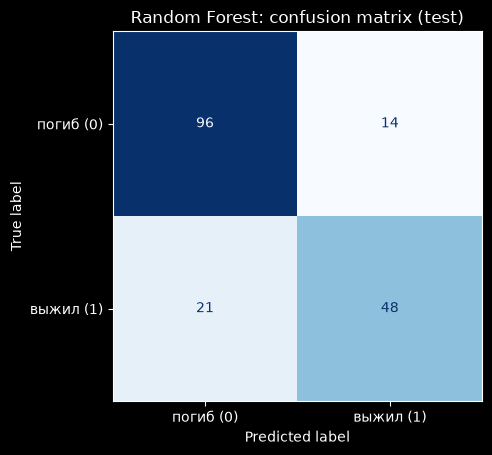

In [19]:
from sklearn.ensemble import RandomForestClassifier

rf = tune(
    "Random Forest",
    RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1),
    {"model__max_depth": [4, 6, 8, None], "model__min_samples_leaf": [1, 3, 5]},
    scale=False,
)
evaluate("Random Forest", rf)

Embarked_Q      0.002
Title_Rare      0.005
Embarked_C      0.006
Embarked_S      0.007
Title_Master    0.009
Parch           0.012
SibSp           0.022
Title_Miss      0.041
Age             0.047
FamilySize      0.049
Title_Mrs       0.049
HasCabin        0.061
Fare            0.077
Pclass          0.078
Sex_female      0.160
Sex_male        0.172
Title_Mr        0.202
dtype: float64


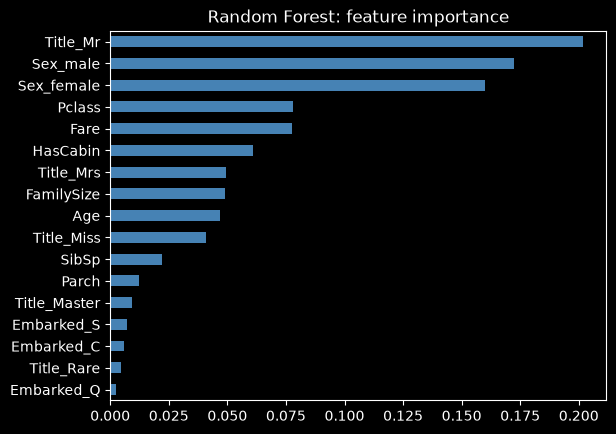

In [20]:
rf_imp = importances(rf)
print(rf_imp.round(3))
rf_imp.plot(kind="barh", color="steelblue")
plt.title("Random Forest: feature importance")
plt.show()

**Анализ Random Forest:**
- Лучшие параметры по CV: `max_depth=4`, `min_samples_leaf=3` — тоже довольно простые деревья. CV F1 = 0.775 — **лучший по кросс-валидации** среди всех моделей.
- На тесте F1 = 0.733 (train 0.778): небольшой разрыв, переобучение умеренное. На тесте лес оказался чуть хуже одиночного дерева — на маленьком тесте (179 пассажиров, 69 выживших) разница в 2–3 пассажира меняет F1 на ~0.03, это в пределах случайности.
- **Важность признаков** распределена шире, чем у дерева: `Title_Mr` (0.20), `Sex_male` (0.17), `Sex_female` (0.16), затем `Pclass` и `Fare` (≈0.08). Лес использует **и** титул, **и** пол: каждое дерево видит случайный набор признаков, поэтому важность «делится» между похожими признаками. По сути топ лесa и дерева совпадает: **пол/титул → класс каюты**.

## 10. Gradient Boosting

Деревья строятся **последовательно**: каждое новое неглубокое дерево исправляет ошибки уже построенного ансамбля; вклад каждого дерева умножается на `learning_rate`. Параметры выбираем по CV.

Gradient Boosting: лучшие параметры {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 300}, CV F1 = 0.768
Gradient Boosting


,Accuracy,Precision,Recall,F1
train,0.912,0.913,0.850,0.880
test,0.810,0.787,0.696,0.738


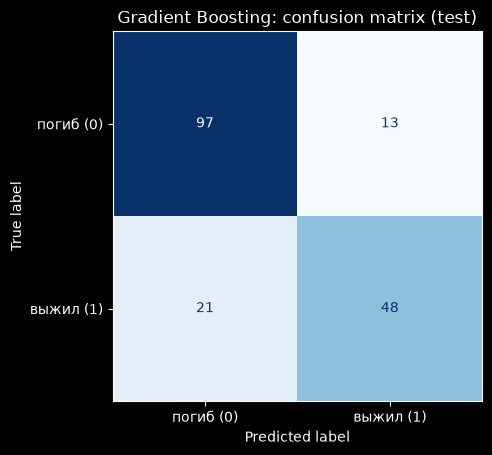

In [21]:
from sklearn.ensemble import GradientBoostingClassifier

gb = tune(
    "Gradient Boosting",
    GradientBoostingClassifier(random_state=RANDOM_STATE),
    {"model__n_estimators": [100, 300], "model__learning_rate": [0.05, 0.1],
     "model__max_depth": [2, 3]},
    scale=False,
)
evaluate("Gradient Boosting", gb)

Embarked_C      0.000
Parch           0.001
Embarked_Q      0.002
Title_Mrs       0.003
SibSp           0.003
Title_Master    0.005
Title_Miss      0.005
Embarked_S      0.012
Title_Rare      0.015
HasCabin        0.048
Sex_male        0.060
FamilySize      0.072
Age             0.098
Pclass          0.099
Sex_female      0.153
Fare            0.156
Title_Mr        0.268
dtype: float64


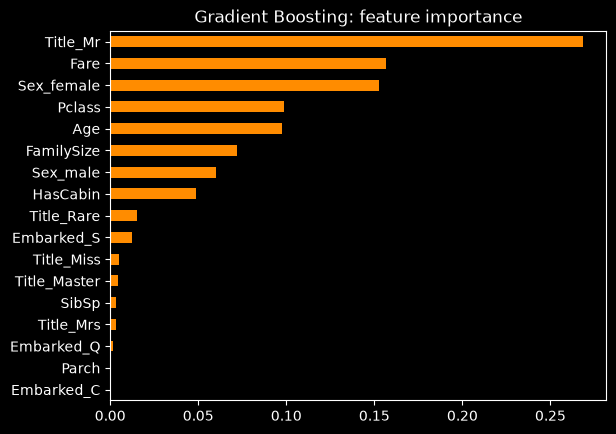

In [22]:
gb_imp = importances(gb)
print(gb_imp.round(3))
gb_imp.plot(kind="barh", color="darkorange")
plt.title("Gradient Boosting: feature importance")
plt.show()

**Анализ Gradient Boosting:**
- Лучшие параметры: 300 деревьев глубины 2, `learning_rate=0.1`. CV F1 = 0.768.
- На тесте F1 = 0.738 — почти как у леса (0.733). Train F1 = 0.88 заметно выше теста — бустинг сильнее подстраивается под train (больше переобучение, чем у леса).
- **Важность признаков:** `Title_Mr` (0.27), `Fare` (0.16), `Sex_female` (0.15), `Pclass` и `Age` (≈0.10). По сравнению с лесом бустинг больше опирается на **непрерывные** признаки `Fare` и `Age`: у них много возможных порогов разбиения, и последовательные деревья используют их для «тонких» поправок. Impurity-based важность вообще склонна завышать признаки с большим числом уникальных значений.

## 11. Support Vector Machine

SVM ищет **разделяющую границу с максимальным зазором** между классами: граница проходит так, чтобы ближайшие к ней объекты обоих классов (опорные векторы) были как можно дальше. Ядро RBF позволяет строить **нелинейную** границу — оно оценивает сходство объектов через расстояние между ними.

**Нужно ли масштабирование?** **Да.** И сам зазор, и RBF-ядро вычисляются через **расстояния** между объектами. Без масштабирования признак с большим разбросом (`Fare` до 512) доминировал бы в расстоянии, а `Sex_female` (0/1) почти ничего не значил бы. Поэтому здесь `scale=True`.

Параметры: `C` — штраф за ошибки на train (больше C → граница сложнее, риск переобучения), `gamma` — «радиус влияния» объекта в RBF-ядре.

SVM: лучшие параметры {'model__C': 10, 'model__gamma': 0.01}, CV F1 = 0.767
SVM


,Accuracy,Precision,Recall,F1
train,0.834,0.814,0.736,0.773
test,0.844,0.825,0.754,0.788


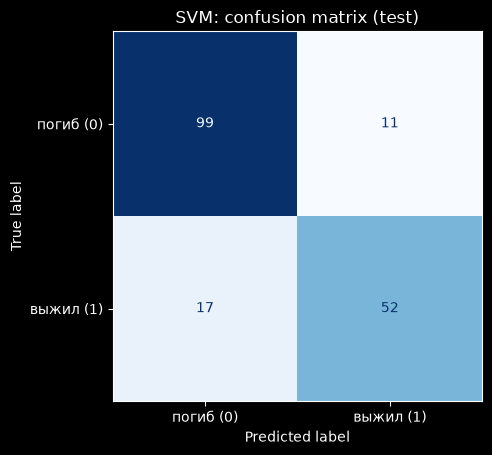

In [23]:
from sklearn.svm import SVC

svm = tune(
    "SVM",
    SVC(kernel="rbf", random_state=RANDOM_STATE),
    {"model__C": [0.1, 1, 10], "model__gamma": ["scale", 0.01, 0.1]},
    scale=True,
)
evaluate("SVM", svm)

**Анализ SVM:**
- Лучшие параметры: `C=10`, `gamma=0.01` (широкое ядро → довольно гладкая граница). CV F1 = 0.767.
- На тесте **F1 = 0.788 — лучший результат** среди всех моделей; Accuracy 0.844. Train (0.773) ≈ test — переобучения нет.
- Меньше всех пропусков (FN = 17) при небольшом числе ложных тревог (FP = 11).
- SVM не даёт feature importance напрямую (граница задана через опорные векторы в преобразованном пространстве), поэтому для анализа важности используем деревья.

## 12. K-Nearest Neighbors

KNN не строит модель в явном виде: для нового пассажира находит **k ближайших** пассажиров из train (по евклидову расстоянию в пространстве признаков) и предсказывает класс большинства среди них.

**Почему масштаб особенно важен для KNN?** Весь алгоритм — это сравнение расстояний. Расстояние считается по всем признакам сразу: √((ΔFare)² + (ΔAge)² + (ΔSex)² + ...). Без масштабирования разница в цене билета на 30 даёт вклад 900, а разница в поле — всего 1. «Ближайшими соседями» окажутся пассажиры с похожей ценой билета, **независимо от пола** — а пол самый важный признак! Проверим это экспериментом.

In [24]:
from sklearn.neighbors import KNeighborsClassifier

# Эксперимент: KNN БЕЗ масштабирования (k подбираем так же, по CV)
knn_raw = tune(
    "KNN без масштабирования",
    KNeighborsClassifier(),
    {"model__n_neighbors": list(range(3, 26, 2))},
    scale=False,
)
print("F1 на тесте без масштабирования:", round(f1_score(y_test, knn_raw.predict(X_test)), 3))

KNN без масштабирования: лучшие параметры {'model__n_neighbors': 7}, CV F1 = 0.653
F1 на тесте без масштабирования: 0.594


Без масштабирования KNN проваливается: CV F1 ≈ 0.65, на тесте F1 ≈ 0.59 — **ниже порога 0.70**. Соседи подбираются в основном по `Fare` и `Age`, а пол почти игнорируется. Теперь — с масштабированием.

KNN: лучшие параметры {'model__n_neighbors': 13, 'model__weights': 'uniform'}, CV F1 = 0.750
KNN


,Accuracy,Precision,Recall,F1
train,0.838,0.824,0.736,0.778
test,0.810,0.761,0.739,0.750


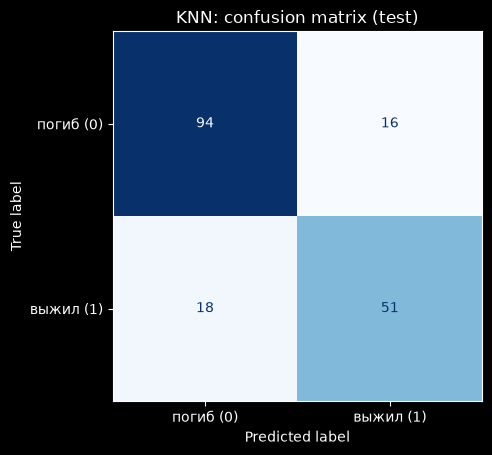

In [25]:
knn = tune(
    "KNN",
    KNeighborsClassifier(),
    {"model__n_neighbors": list(range(3, 26, 2)), "model__weights": ["uniform", "distance"]},
    scale=True,
)
evaluate("KNN", knn)

**Анализ KNN:**
- С масштабированием: k = 13 соседей, CV F1 = 0.75, на тесте **F1 = 0.75** — рост с 0.59 до 0.75 только за счёт масштабирования признаков.
- Почему k = 13, а не 1: при k = 1 модель повторяла бы метку одного ближайшего пассажира и переобучалась бы на шум; при очень большом k — сглаживала бы всё к самому частому классу. Значение выбрано по CV.
- Больше всех ложных тревог (FP = 16): среди соседей женщин 3-го класса много выживших, и KNN «спасает» тех, кто погиб.

## 13. Честное сравнение моделей

Все модели обучены на одном train, гиперпараметры выбраны по 5-fold CV на train (метрика F1), оценка — на одном и том же тесте.

In [26]:
results_df = pd.DataFrame(results).T.round(3)
results_df["F1 > 0.70"] = results_df["F1"] > 0.70
results_df

,Accuracy,Precision,Recall,F1,F1 > 0.70
Dummy (most frequent),0.615,0.000,0.000,0.000,False
Decision Tree,0.832,0.820,0.725,0.769,True
Random Forest,0.804,0.774,0.696,0.733,True
Gradient Boosting,0.810,0.787,0.696,0.738,True
SVM,0.844,0.825,0.754,0.788,True
KNN,0.810,0.761,0.739,0.750,True


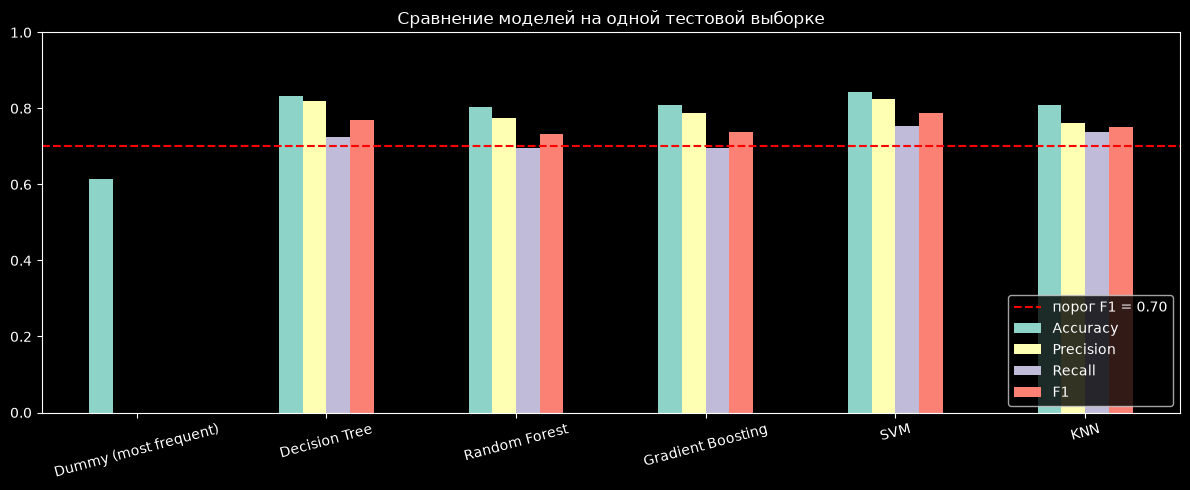

In [27]:
results_df[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", rot=15, figsize=(12, 5))
plt.axhline(0.70, color="red", ls="--", label="порог F1 = 0.70")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.title("Сравнение моделей на одной тестовой выборке")
plt.tight_layout()
plt.show()

In [28]:
from sklearn.metrics import confusion_matrix

rows = []
for name, pred in predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"модель": name, "TN": tn, "FP": fp, "FN": fn, "TP": tp})
pd.DataFrame(rows).set_index("модель")

,TN,FP,FN,TP
модель,,,,
Dummy (most frequent),110,0,69,0
Decision Tree,99,11,19,50
Random Forest,96,14,21,48
Gradient Boosting,97,13,21,48
SVM,99,11,17,52
KNN,94,16,18,51


**Выводы по сравнению:**
- **Порог F1 > 0.70 превзошли все пять моделей.** Dummy — F1 = 0.
- **Лучший результат на тесте — SVM (F1 = 0.788)**, затем Decision Tree (0.769), KNN (0.75), Gradient Boosting (0.738), Random Forest (0.733). По **кросс-валидации** все модели очень близки (0.75–0.775), а лучший — Random Forest. Разница между моделями на тесте — 2–5 пассажиров из 179, т.е. во многом **случайность маленькой тестовой выборки**. Честный вывод: качество моделей сопоставимо.
- **Почему простые модели не хуже сложных:** в данных доминирует одна сильная и простая закономерность — «женщины и дети, особенно из 1–2 класса, выжили; взрослые мужчины — нет». Её хорошо улавливает даже дерево глубины 3. Данных мало (712 пассажиров), а сложные ансамбли легче подстраиваются под шум.
- **SVM и KNN** конкурентоспособны только **после масштабирования** (KNN без него — 0.59).
- У всех моделей **Precision > Recall** и **FN > FP**: модели чаще пропускают выживших (в основном мужчин), чем ошибочно «спасают» погибших. Выжившие мужчины — меньшинство в своей группе, и модель их почти не может отличить.

## 14. Feature importance — сравнение моделей

              Decision Tree  Random Forest  Gradient Boosting
Title_Mr              0.630          0.202              0.268
Sex_male              0.000          0.172              0.060
Sex_female            0.000          0.160              0.153
Pclass                0.155          0.078              0.099
Fare                  0.008          0.077              0.156
HasCabin              0.050          0.061              0.048
Title_Mrs             0.000          0.049              0.003
FamilySize            0.082          0.049              0.072
Age                   0.013          0.047              0.098
Title_Miss            0.000          0.041              0.005
SibSp                 0.000          0.022              0.003
Parch                 0.000          0.012              0.001
Title_Master          0.000          0.009              0.005
Embarked_S            0.000          0.007              0.012
Embarked_C            0.000          0.006              0.000
Title_Ra

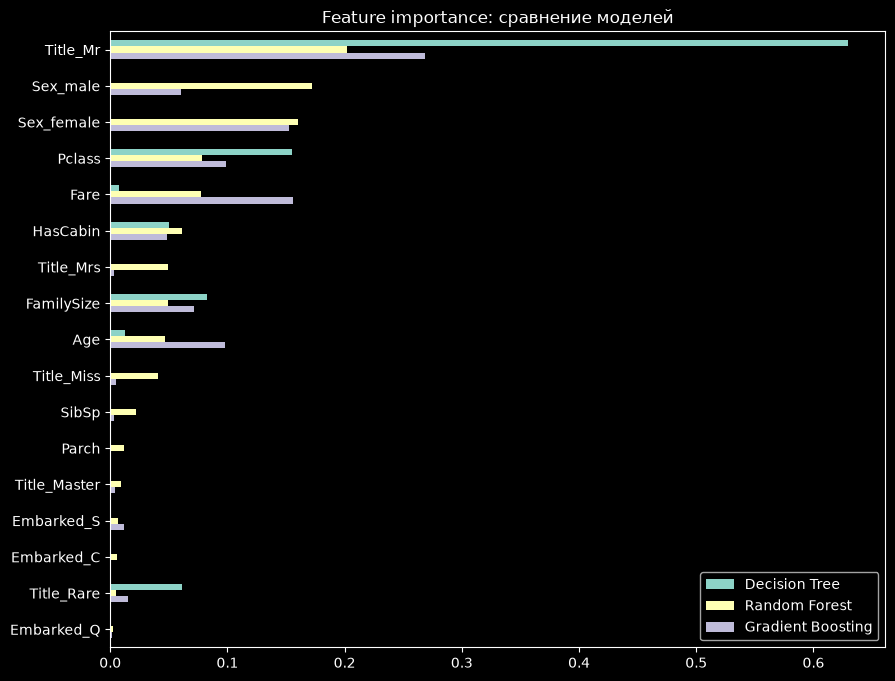

Топ-4 Decision Tree: ['Title_Mr', 'Pclass', 'FamilySize', 'Title_Rare']
Топ-4 Random Forest: ['Title_Mr', 'Sex_male', 'Sex_female', 'Pclass']
Топ-4 Gradient Boosting: ['Title_Mr', 'Fare', 'Sex_female', 'Pclass']


In [29]:
imp = pd.DataFrame({
    "Decision Tree": tree_imp,
    "Random Forest": rf_imp,
    "Gradient Boosting": gb_imp,
}).fillna(0).sort_values("Random Forest", ascending=False)
print(imp.round(3))

imp.plot(kind="barh", figsize=(10, 8)).invert_yaxis()
plt.title("Feature importance: сравнение моделей")
plt.show()

for name, s in [("Decision Tree", tree_imp), ("Random Forest", rf_imp), ("Gradient Boosting", gb_imp)]:
    print(f"Топ-4 {name}:", list(s.sort_values(ascending=False).index[:4]))

**Выводы:**
1. **Главные признаки во всех трёх моделях** — пол / титул (`Title_Mr`, `Sex_male`, `Sex_female`) и социальный статус (`Pclass`, `Fare`). Это полностью совпадает с EDA: пол — самый сильный фактор (74% vs 19%), класс — второй (63% / 47% / 24%).
2. **Модели по-разному распределяют важность между похожими признаками.** `Title_Mr`, `Sex_male` и `Sex_female` несут почти одинаковую информацию. Одиночное дерево взяло только `Title_Mr` (0.63), а `Sex` получил 0; лес «размазал» важность между всеми тремя; бустинг — между `Title_Mr` и `Sex_female`. Поэтому важность отдельного признака у коррелированных признаков нужно читать вместе: суммарно «пол/титул» ≈ 0.5–0.6 во всех моделях.
3. `Age` и `FamilySize` — среднее влияние (дети и семьи средних размеров выживали чаще), `Embarked` почти не важен — его влияние в EDA объяснялось связью с классом.
4. Бустинг завышает `Fare` и `Age` относительно других моделей — у непрерывных признаков больше возможных порогов, и impurity-based importance это поощряет.

**Можно ли утверждать, что важный признак — причина выживания?** **Нет.**
- Feature importance показывает, насколько признак **помогает модели предсказывать**, т.е. отражает **связь в данных**, а не причину.
- Пример: `Fare` важен, но дорогой билет сам по себе никого не спас — он связан с 1-м классом, а тот — с расположением кают ближе к шлюпкам и приоритетом при посадке. Аналогично `HasCabin`: известность номера каюты — следствие того, что пассажир из 1-го класса, а не причина спасения.
- Даже для пола причинный механизм — **правило эвакуации** «женщины и дети первыми», а не пол как биологический факт.
- Важность делится между коррелированными признаками произвольно (пример `Sex` и `Title_Mr`), поэтому даже её величина неоднозначна.
- Для причинных выводов нужен контролируемый эксперимент или специальные методы причинного анализа, а не наблюдательные данные.

## 15. Анализ ошибок лучшей модели

Лучшая модель по F1 на тесте (выбор лучшей здесь — только для анализа; гиперпараметры подбирались по CV).

Лучшая модель по F1 на тесте: SVM
ошибка
верно    151
FN        17
FP        11
Name: count, dtype: int64


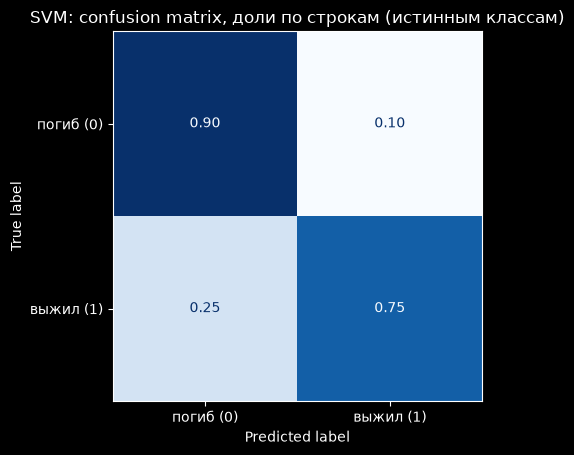

In [30]:
best_name = results_df.drop(index="Dummy (most frequent)")["F1"].idxmax()
print("Лучшая модель по F1 на тесте:", best_name)

err = df.loc[X_test.index, ["Name", "Sex", "Age", "Pclass", "Title", "FamilySize", "Fare", "Survived"]].copy()
err["pred"] = predictions[best_name]
err["ошибка"] = np.select(
    [(err["Survived"] == 0) & (err["pred"] == 1), (err["Survived"] == 1) & (err["pred"] == 0)],
    ["FP", "FN"], default="верно")
print(err["ошибка"].value_counts())

ConfusionMatrixDisplay.from_predictions(
    y_test, predictions[best_name], display_labels=["погиб (0)", "выжил (1)"],
    cmap="Blues", colorbar=False, normalize="true", values_format=".2f")
plt.title(f"{best_name}: confusion matrix, доли по строкам (истинным классам)")
plt.show()

**Выводы:**
- Из 179 тестовых пассажиров SVM ошибся на 28: **17 False Negative** (выживших назвал погибшими) и **11 False Positive**. Пропуски выживших встречаются чаще.
- Нормированная матрица: из реально погибших верно распознано ≈90%, из реально выживших — ≈75%. Модели труднее находить выживших.

In [31]:
def group_errors(col):
    g = err.groupby(col, observed=True)
    return pd.DataFrame({
        "пассажиров": g.size(),
        "доля выживших": g["Survived"].mean(),
        "доля ошибок": g["ошибка"].apply(lambda s: (s != "верно").mean()),
        "FP": g["ошибка"].apply(lambda s: (s == "FP").sum()),
        "FN": g["ошибка"].apply(lambda s: (s == "FN").sum()),
    }).round(2)

err["Sex_Pclass"] = err["Sex"] + "_" + err["Pclass"].astype(str)
print(group_errors("Sex_Pclass"))
print()
print(group_errors("Title"))

            пассажиров  доля выживших  доля ошибок  FP  FN
Sex_Pclass                                                
female_1            15           0.93         0.07   1   0
female_2            18           0.94         0.06   1   0
female_3            28           0.50         0.32   9   0
male_1              30           0.37         0.30   0   9
male_2              16           0.19         0.12   0   2
male_3              72           0.14         0.08   0   6

        пассажиров  доля выживших  доля ошибок  FP  FN
Title                                                 
Master           9           0.67         0.00   0   0
Miss            41           0.68         0.20   8   0
Mr             105           0.17         0.16   0  17
Mrs             19           0.84         0.16   3   0
Rare             5           0.20         0.00   0   0


**Для каких групп модель ошибается чаще всего:**
- **Женщины 3-го класса:** 32% ошибок, **все — FP** (9). Выжила ровно половина женщин 3-го класса, и модель, видя «женщина», чаще предсказывает «выжила».
- **Мужчины 1-го класса:** 30% ошибок, **все — FN** (9). Выжило 37% мужчин 1-го класса — больше, чем других мужчин, но всё равно меньшинство, и модель предсказывает «погиб».
- Для групп, где исход почти однозначен (женщины 1–2 класса — выжили >90%, мужчины 2–3 класса — погибли >80%), ошибок мало (6–12%).
- По титулам: **все ошибки на Mr — FN, все ошибки на Miss/Mrs — FP**. Модель фактически выучила правило «женщина → выжила, мужчина → погиб» с поправками на класс и возраст и ошибается на тех, кто это правило нарушает.

In [32]:
err[err["ошибка"] != "верно"].sort_values(["ошибка", "Sex", "Pclass"])

,Name,Sex,Age,Pclass,Title,FamilySize,Fare,Survived,pred,ошибка,Sex_Pclass
712,"Taylor, Mr. Elmer Zebley",male,48.0,1,Mr,2,52.0000,1,0,FN,male_1
701,"Silverthorne, Mr. Spencer Victor",male,35.0,1,Mr,1,26.2875,1,0,FN,male_1
447,"Seward, Mr. Frederic Kimber",male,34.0,1,Mr,1,26.5500,1,0,FN,male_1
690,"Dick, Mr. Albert Adrian",male,31.0,1,Mr,2,57.0000,1,0,FN,male_1
55,"Woolner, Mr. Hugh",male,NaN,1,Mr,1,35.5000,1,0,FN,male_1
23,"Sloper, Mr. William Thompson",male,28.0,1,Mr,1,35.5000,1,0,FN,male_1
607,"Daniel, Mr. Robert Williams",male,27.0,1,Mr,1,30.5000,1,0,FN,male_1
587,"Frolicher-Stehli, Mr. Maxmillian",male,60.0,1,Mr,3,79.2000,1,0,FN,male_1
484,"Bishop, Mr. Dickinson H",male,25.0,1,Mr,2,91.0792,1,0,FN,male_1
17,"Williams, Mr. Charles Eugene",male,NaN,2,Mr,1,13.0000,1,0,FN,male_2


**Разбор конкретных ошибок:**
- **FN, мужчины 1-го класса** (например, *Taylor, Mr. Elmer Zebley*, 48 лет; *Bishop, Mr. Dickinson H*, 25 лет): по признакам — взрослые мужчины, а таких выживало мало. Почему именно они спаслись (место на палубе в момент эвакуации, оказались рядом с недоукомплектованной шлюпкой, помогли другим), в данных нет — это **неустранимая для модели случайность**.
- **FN, мужчины 3-го класса** (например, *Tornquist, Mr. William Henry* — билет за 0): по всем признакам — типичный погибший (выжило лишь 14% таких). Модель не может их распознать, не запоминая конкретных людей.
- **FP, женщины 3-го класса** (например, *Ahlin, Mrs. Johan*, *Canavan, Miss. Mary*, *Bourke, Miss. Mary* — у части нет даже возраста): «женщина» сильно тянет к классу «выжила», но в 3-м классе каюты были в нижних частях корабля, далеко от шлюпок.
- **FP, *Allison, Miss. Helen Loraine*** — 2-летняя девочка из 1-го класса, по всем признакам должна была выжить (97% женщин 1-го класса спаслись). Это известный трагический случай: семья искала потерявшегося сына и не успела на шлюпку. Пример того, что исход определяли и обстоятельства, которых нет в данных.

**Итог:** модель ошибается на «нетипичных» для своей группы пассажирах. Улучшить это без дополнительной информации (место нахождения во время эвакуации, номер шлюпки и т.п.) практически невозможно.

### 15.1 Не связано ли качество с «идентифицирующими» признаками?

Наши модели **не используют** `PassengerId`, `Name`, `Ticket`, номер `Cabin` — признаки, которые фактически идентифицируют конкретного пассажира. Проверим, что было бы, если бы мы оставили `PassengerId`.

In [33]:
# Проверка: что будет, если добавить в модель «идентифицирующий» признак PassengerId
leak_features = num_features + ["PassengerId"]
X_leak = df[leak_features + cat_features]
Xl_train, Xl_test = X_leak.loc[X_train.index], X_leak.loc[X_test.index]

leak_prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), leak_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_features),
])
rf_leak = Pipeline([("prep", leak_prep),
                    ("model", RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1))])
rf_leak.fit(Xl_train, y_train)

rf_plain = Pipeline([("prep", make_preprocessor(scale=False)),
                     ("model", RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1))])
rf_plain.fit(X_train, y_train)

from sklearn.model_selection import cross_val_score
cv_plain = cross_val_score(rf_plain, X_train, y_train, cv=cv, scoring="f1").mean()
cv_leak = cross_val_score(rf_leak, Xl_train, y_train, cv=cv, scoring="f1").mean()

print("Корреляция PassengerId с Survived:", round(df["PassengerId"].corr(df["Survived"]), 3))
print("Random Forest без ограничений глубины:")
print("  без PassengerId: F1 train =", round(f1_score(y_train, rf_plain.predict(X_train)), 3),
      " F1 test =", round(f1_score(y_test, rf_plain.predict(X_test)), 3), " CV F1 =", round(cv_plain, 3))
print("  с PassengerId:   F1 train =", round(f1_score(y_train, rf_leak.predict(Xl_train)), 3),
      " F1 test =", round(f1_score(y_test, rf_leak.predict(Xl_test)), 3), " CV F1 =", round(cv_leak, 3))
leak_imp = pd.Series(rf_leak.named_steps["model"].feature_importances_,
                     index=[n.split("__", 1)[1] for n in leak_prep.get_feature_names_out()])
print("\nВажность PassengerId:", round(leak_imp["PassengerId"], 3),
      "— место", int(leak_imp.rank(ascending=False)["PassengerId"]), "из", len(leak_imp))

Корреляция PassengerId с Survived: -0.005
Random Forest без ограничений глубины:
  без PassengerId: F1 train = 0.983  F1 test = 0.745  CV F1 = 0.757
  с PassengerId:   F1 train = 1.0  F1 test = 0.759  CV F1 = 0.753

Важность PassengerId: 0.156 — место 2 из 18


**Выводы:**
- `PassengerId` никак не связан с выживанием (корреляция ≈ 0), но лес с ним показывает **F1 = 1.0 на train** и даёт ему **2-ю по величине важность**. Модель использует номер для **запоминания** конкретных пассажиров: «пассажир №713 выжил».
- На кросс-валидации и тесте качество с `PassengerId` не становится лучше в значимой мере — разница в пределах случайности: номер ничего не обобщает на новых пассажиров. Зато feature importance становится **обманчивой** — бессмысленный признак выглядит одним из главных.
- Аналогично работали бы `Name` и `Ticket` (почти уникальные значения). Поэтому их правильно исключить: высокое качество наших моделей объясняется **осмысленными** признаками — полом, титулом, классом, возрастом, — а не запоминанием пассажиров.

## 16. Итоговые выводы

1. **Данные:** 891 пассажир, выжило 38% (дисбаланс классов → Accuracy обманчива, основная метрика F1). Пропуски: `Age` 20% (медиана), `Cabin` 77% (→ признак `HasCabin`), `Embarked` 2 (самое частое значение). Дубликатов нет.
2. **Признаки:** удалены идентифицирующие `PassengerId`, `Name`, `Ticket`, номер `Cabin`; созданы `Title`, `FamilySize`, `HasCabin`. Категориальные признаки — One-Hot. Вся предобработка внутри `Pipeline` → параметры считаются только на train.
3. **Разбиение:** 80/20 со стратификацией, `random_state=42`, одно разбиение для всех моделей; гиперпараметры — по 5-fold CV (F1) на train.
4. **Baseline** (всегда «погиб»): Accuracy 0.62, **F1 = 0**.
5. **Все пять моделей прошли порог F1 > 0.70:** SVM 0.788 (лучший на тесте), Decision Tree 0.769, KNN 0.75, Gradient Boosting 0.738, Random Forest 0.733. По CV модели близки (0.75–0.775).
6. **Масштабирование** критично для KNN (F1 0.59 → 0.75) и SVM; для деревьев не нужно.
7. **Переобучение:** неограниченное дерево — F1 0.98 на train и 0.73 на test; ограничение глубины до 3 решило проблему.
8. **Главные признаки** во всех деревьях — пол/титул и класс (`Title_Mr`, `Sex`, `Pclass`, `Fare`), что совпадает с EDA. Важность ≠ причинность.
9. **Ошибки:** модель фактически выучила «женщины и дети первыми» с поправкой на класс; ошибается на мужчинах 1-го класса (FN) и женщинах 3-го класса (FP).